# Ranked MNDWI per site after exlusing any sites with SCL to ignore

In [1]:
import base64
import datetime
import html as html_module
import io
import os
import sys
import zoneinfo
import pathlib

import dotenv
import geopandas
import matplotlib.pyplot as plt
import numpy
import odc.stac
import pandas
import planetary_computer
import plotly.express as px
import rasterio
import rasterio.features
import requests
import xarray
from IPython.display import FileLink, display

module_path = pathlib.Path.cwd().parent / 'scripts'
import sys
if str(module_path) not in sys.path:
    sys.path.append(str(module_path))
import utils
import sentinel2

In [2]:
data_path = utils.get_data_path()
site_polygons_path = data_path / "site_polygons"
output_root = data_path / "analysis" / "all_sites"

In [3]:
all_training_sites =  ["Ihutai", "CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua", "Purau",
              "IveyBay_Nov25", "IveyBay_Feb26", "LeftBank_Nov25", "LeftBank_Feb26", "Paremata_Nov25", "Paremata_Feb26",
              "Paremata_Feb25", "ThePoint_Nov25", "ThePoint_Feb26", "Takapuwahia_Nov25", "Takapuwahia_Feb26", "IveyBay_ThePoint_LeftBank_Oct24"]

In [8]:
site  = all_training_sites[0]
tide_info = pandas.read_csv(output_root / site / f"{site}_2016-2025_low_tide_dry_area.csv")

In [17]:
def cards_for_plot(tide_df):

    for scene_index, row in tide_df.iterrows():
        rgb = numpy.stack(
            [
                satellite_data[band].isel(time=scene_index).values
                for band in sentinel2.RGB_BANDS
            ],
            axis=-1,
        ).astype(numpy.float32)
        rgb_valid = numpy.isfinite(rgb).all(axis=-1) & (rgb > 0).all(axis=-1)
        rgb_display = numpy.ones_like(rgb)
        if rgb_valid.any():
            for channel in range(3):
                pixels = rgb[..., channel][rgb_valid]
                low, high = numpy.percentile(pixels, [2, 98])
                if high > low:
                    rgb_display[..., channel] = numpy.clip(
                        (rgb[..., channel] - low) / (high - low), 0, 1
                    )
        rgb_display[~rgb_valid] = 1
        low_local = pandas.Timestamp(row["nearest_low_tide_time_utc"]).tz_convert(
            "Pacific/Auckland"
        )
        caption = (
            f"Dry {row['dry_area_pct']:.1f}% | MNDWI {row['mean_mndwi']:.3f} | "
            f"Low {low_local:%d %b %H:%M} ({row['time_from_low_tide']}, "
            f"{row['nearest_low_tide_height_msl']:.2f} m MSL) | Valid SCL % {row['valid_scl_pct']}"
        )
        safe_date = html_module.escape(str(row["date"]))

        rgb_buffer = io.BytesIO()
        rgb_figure, rgb_axis = plt.subplots(figsize=(5, 3.75))
        rgb_axis.imshow(rgb_display)
        rgb_axis.axis("off")
        rgb_figure.savefig(
            rgb_buffer,
            format="jpg",
            dpi=90,
            bbox_inches="tight",
            pad_inches=0,
            pil_kwargs={"quality": 84, "optimize": True},
        )
        plt.close(rgb_figure)
        rgb_base64 = base64.b64encode(rgb_buffer.getvalue()).decode("ascii")
        rgb_cards_by_index[scene_index] = (
            f'<article class="scene"><h2>{safe_date}</h2>'
            f'<img src="data:image/jpeg;base64,{rgb_base64}" '
            f'alt="{site_name} RGB {safe_date}">'
            f'<div class="caption">{caption}</div></article>'
        )

        scl_array = satellite_data["SCL"].isel(time=scene_index).values
        scl_rgb = numpy.full((*scl_array.shape, 3), 238, dtype=numpy.uint8)
        for class_code, _, color in scl_classes:
            rgb_color = tuple(int(color[index:index + 2], 16) for index in (1, 3, 5))
            scl_rgb[(scl_array == class_code) & site_mask_values] = rgb_color
        scl_buffer = io.BytesIO()
        scl_figure, scl_axis = plt.subplots(figsize=(5, 3.75))
        scl_axis.imshow(scl_rgb)
        scl_axis.axis("off")
        scl_figure.savefig(
            scl_buffer,
            format="jpg",
            dpi=90,
            bbox_inches="tight",
            pad_inches=0,
            pil_kwargs={"quality": 90, "optimize": True},
        )
        plt.close(scl_figure)
        scl_base64 = base64.b64encode(scl_buffer.getvalue()).decode("ascii")
        scl_cards_by_index[scene_index] = (
            f'<article class="scene"><h2>{safe_date}</h2>'
            f'<img src="data:image/jpeg;base64,{scl_base64}" '
            f'alt="{site_name} SCL {safe_date}">'
            f'<div class="caption">{caption}</div></article>'
        )
    return rgb_cards_by_index, scl_cards_by_index

In [18]:
rgb_cards_by_index, scl_cards_by_index = cards_for_plot(tide_info[tide_info['valid_scl_pct'] > 99])

NameError: name 'satellite_data' is not defined

<Axes: >

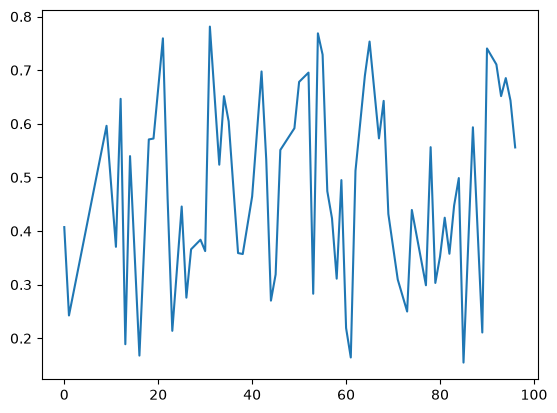

In [19]:
tide_info[tide_info['valid_scl_pct'] > 99]["mean_mndwi"].plot()

In [22]:
len(all_training_sites)

20

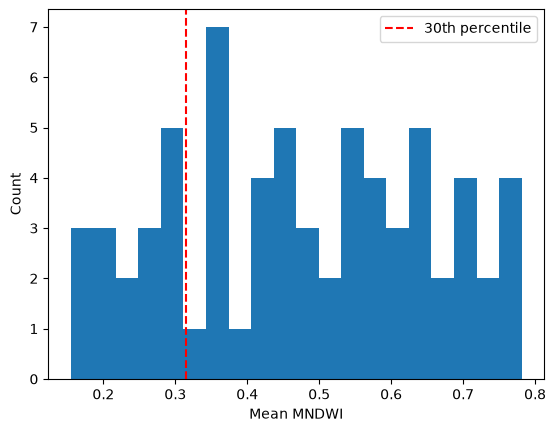

In [21]:
import matplotlib.pyplot as plt

plt.hist(tide_info[tide_info['valid_scl_pct'] > 99]['mean_mndwi'], bins=20)
plt.axvline(
    tide_info['mean_mndwi'].quantile(0.30),
    color='red',
    linestyle='--',
    label='30th percentile'
)
plt.legend()
plt.xlabel("Mean MNDWI")
plt.ylabel("Count")
plt.show()

In [26]:
import matplotlib.pyplot as plt

n_sites = len(all_training_sites)
 
fig, axes = plt.subplots(
nrows=n_sites,
ncols=1,
figsize=(8, 3 * n_sites),
constrained_layout=True
)
 
for ax, site in zip(axes, all_training_sites):

    tide_info = pandas.read_csv(output_root / site / f"{site}_2016-2025_low_tide_dry_area.csv")
    mean_mndwi = tide_info[tide_info['valid_scl_pct'] > 99]["mean_mndwi"]
 
    q30 = mean_mndwi.quantile(0.30)
 
    ax.hist(mean_mndwi, bins=20)
    ax.axvline(q30, color="red", linestyle="--")
     
    ax.set_title(f"{site} (n={len(df)})")
    ax.set_xlabel("Mean MNDWI")
    ax.set_ylabel("Count")
 
plt.show()

SyntaxError: invalid non-printable character U+00A0 (1697872898.py, line 2)

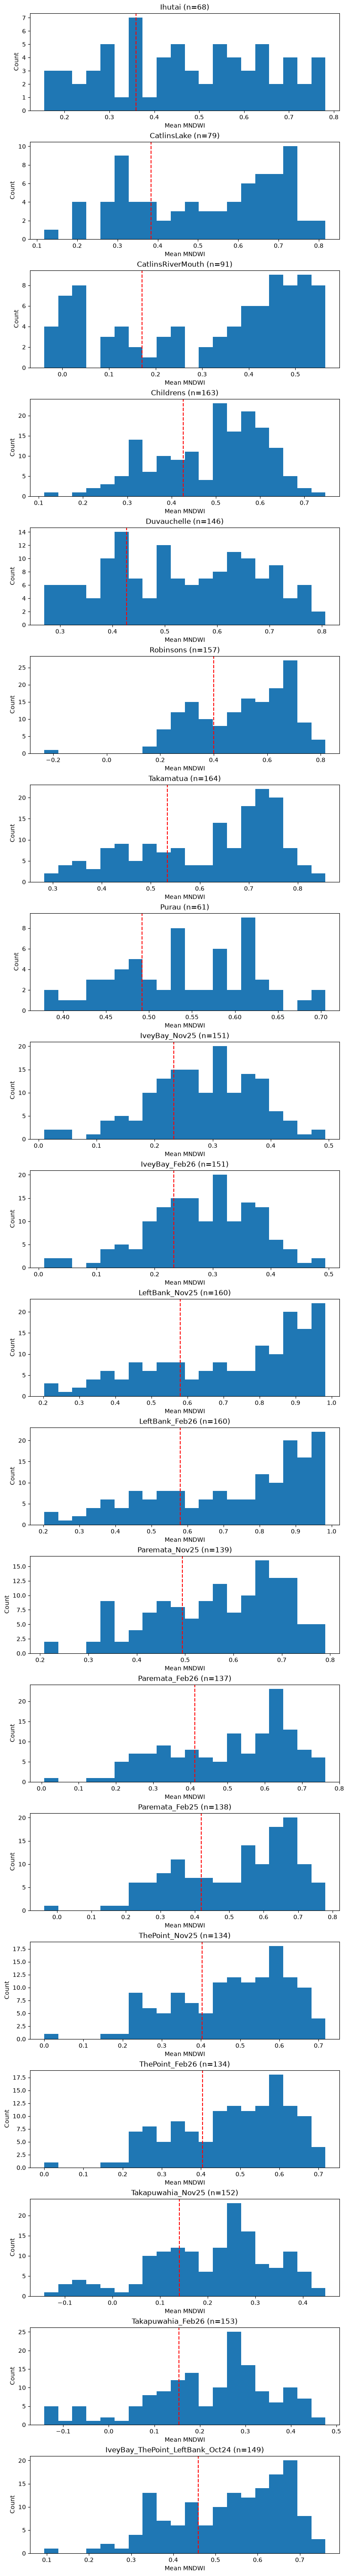

In [32]:
import matplotlib.pyplot as plt

n_sites = len(all_training_sites)

fig, axes = plt.subplots(
nrows=n_sites,
ncols=1,
figsize=(8, 3 * n_sites),
constrained_layout=True
)

for ax, site in zip(axes, all_training_sites):

    tide_info = pandas.read_csv(output_root / site / f"{site}_2016-2025_low_tide_dry_area.csv")
    mean_mndwi = tide_info[tide_info['valid_scl_pct'] > 99]["mean_mndwi"]
    
    q30 = mean_mndwi.quantile(0.30)
    
    ax.hist(mean_mndwi, bins=20)
    ax.axvline(q30, color="red", linestyle="--")
    
    ax.set_title(f"{site} (n={len(mean_mndwi)})")
    ax.set_xlabel("Mean MNDWI")
    ax.set_ylabel("Count")
    
plt.show()